In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load Dataset
dataset_path = "spotify_top_1000_tracks.csv" 
df = pd.read_csv(dataset_path, encoding="utf-8")

# 2. Preprocessing dates at duration
df['release_date'] = pd.to_datetime(df['release_date'], errors='coerce')
df['year'] = df['release_date'].dt.year

# 3. Data Cleaning
df['track_name'] = df['track_name'].str.strip()
df['artist'] = df['artist'].str.strip()
df['album'] = df['album'].str.strip()
df['year'] = df['year'].fillna(0).astype(int)

# Alisin ang unnecessary columns at duplicates
cols_to_drop = ['spotify_url', 'id', 'release_date', 'time_signature', 'key', 'mode']
df = df.drop(columns=[col for col in cols_to_drop if col in df.columns], errors='ignore')
df = df.drop_duplicates(subset=['track_name', 'artist'], keep='first')

print("Data cleaning complete! Final rows:", len(df))

Data cleaning complete! Final rows: 971


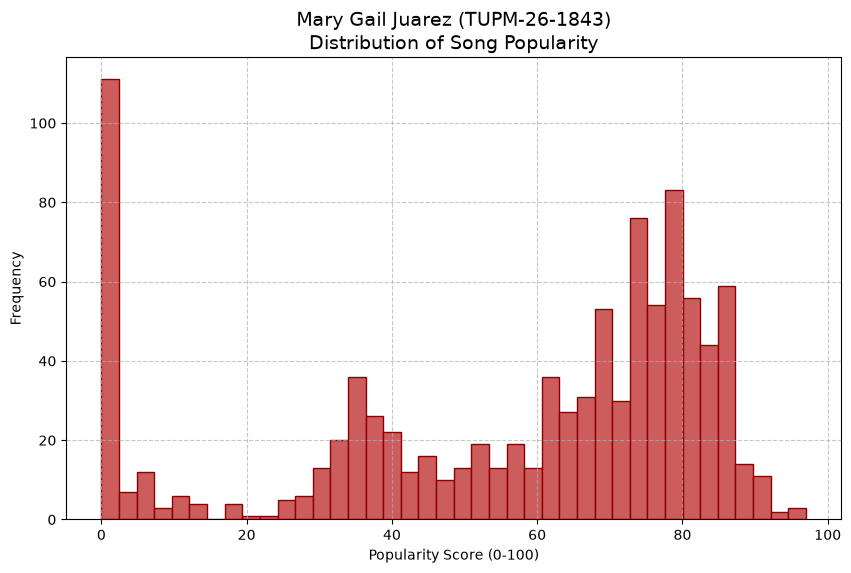

C:\Users\Jane Claide Juarez\AppData\Local\Temp\ipykernel_15768\3879156481.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='year', y='popularity', data=df, palette='viridis')


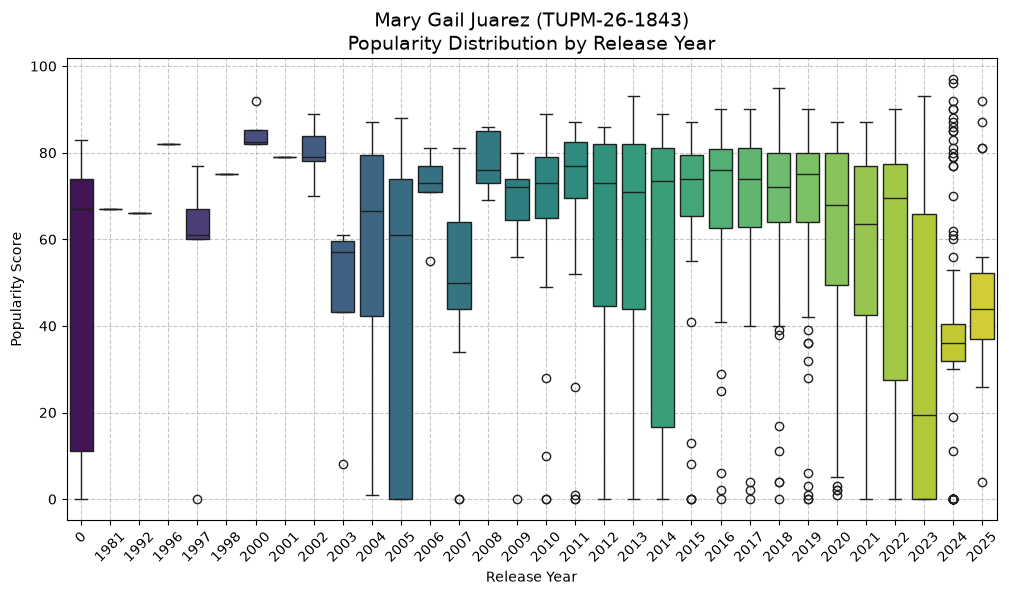

In [3]:
student_name = "Mary Gail Juarez"
student_id = "TUPM-26-1843"

# 1. Histogram: Distribution of Song Popularity
plt.figure(figsize=(10, 6))
plt.hist(df['popularity'], bins=40, color='indianred', edgecolor='darkred')
plt.title(f"{student_name} ({student_id})\nDistribution of Song Popularity", fontsize=14)
plt.xlabel('Popularity Score (0-100)')
plt.ylabel('Frequency')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

# 2. Boxplot: Popularity Distribution by Release Year
plt.figure(figsize=(12, 6))
sns.boxplot(x='year', y='popularity', data=df, palette='viridis')
plt.title(f"{student_name} ({student_id})\nPopularity Distribution by Release Year", fontsize=14)
plt.xlabel('Release Year')
plt.ylabel('Popularity Score')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()